# 01 · Simulating Random Variables

**Covers:** Lab Exercise 1 (the urn) and Assignment 1 (coin/die game, barbershop).

**Idea of the topic:** when a probability is hard to compute, we can *simulate* the
random experiment many times and use the **relative frequency** as an estimate.
By the Law of Large Numbers the frequency converges to the true probability.

Recipe used in every exercise:
1. Write a function that runs the experiment **once**.
2. Run it `N` times (10,000 – 100,000).
3. Count how often the event happened → `estimate = count / N`.
4. Compute the theoretical value by hand and compare.

In [1]:
# On Google Colab you only need to run this once (the libraries are already
# installed locally in the .venv of the repository).
%pip install -q numpy scipy matplotlib

Note: you may need to restart the kernel to use updated packages.

La receta de todo el tema (4 pasos):

Una función que hace el experimento una vez.
Repetirla N veces (100.000).
Contar cuántas veces pasa lo que buscas: estimación = veces / N.
Calcularlo en teoría y comparar. Deberían salir casi iguales

In [2]:
# --- Imports ---------------------------------------------------------------
import numpy as np                  # random numbers and vectorised maths
import matplotlib.pyplot as plt     # plots
from scipy import stats             # probability distributions (pdf, cdf, ...)
from pathlib import Path            # to build the path of the "figures" folder

# Folder where every plot is saved as a PNG (needed for the exam upload).
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

# A random Generator with a fixed seed -> the results are reproducible.
rng = np.random.default_rng(42)

## Exercise 1 · The urn (Lab 1)

An urn contains **3 red, 4 blue and 2 black** balls. We roll a die:
- prime outcome (2, 3, 5) → add a **black** ball,
- outcome 6 → add a **red** ball,
- otherwise (1, 4) → add a **blue** ball.

Then we draw one ball. **What is P(red)?**

### Theory (law of total probability)
Condition on what happened with the die:

$$P(R) = P(6)\cdot\frac{4}{10} + P(\text{not }6)\cdot\frac{3}{10}
       = \frac16\cdot\frac{4}{10} + \frac56\cdot\frac{3}{10} = \frac{19}{60} \approx 0.3167$$

(After adding a ball the urn always has 10 balls; there are 4 red ones only if we added a red one.)

In [3]:
def urn_experiment(rng):
    """Run the experiment ONCE and return the colour of the drawn ball."""
    # Initial content of the urn: colour -> number of balls
    urn = {"red": 3, "blue": 4, "black": 2}

    # Roll a fair die. integers(1, 7) returns 1..6 (the upper bound is excluded!)
    die = rng.integers(1, 7)

    # Add a ball depending on the die outcome
    if die in (2, 3, 5):        # prime numbers
        urn["black"] += 1
    elif die == 6:
        urn["red"] += 1
    else:                       # 1 or 4
        urn["blue"] += 1

    # Draw one ball: each colour is chosen with probability (#balls / total)
    colours = list(urn.keys())
    counts = np.array(list(urn.values()))
    return rng.choice(colours, p=counts / counts.sum())


# Repeat the experiment N times and store all the drawn colours
N = 100_000
draws = np.array([urn_experiment(rng) for _ in range(N)])

# Estimate = relative frequency of "red"
p_red_sim = np.mean(draws == "red")
p_red_theory = (1/6) * (4/10) + (5/6) * (3/10)

print(f"Simulated   P(red) = {p_red_sim:.4f}")
print(f"Theoretical P(red) = {p_red_theory:.4f}  (= 19/60)")

Simulated   P(red) = 0.3171
Theoretical P(red) = 0.3167  (= 19/60)


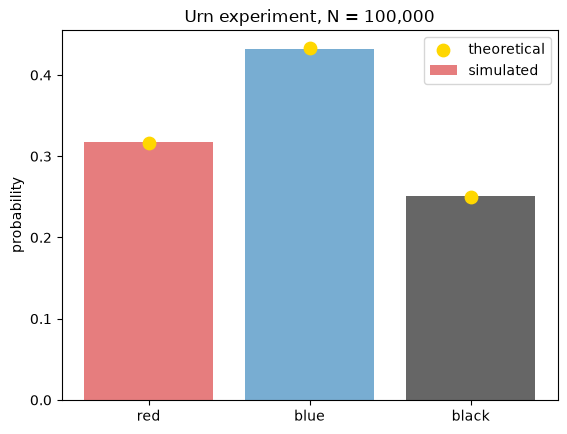

In [4]:
# Compare the three colours: simulated frequency (bars) vs. theory (dots).
# Theory for blue:  die in {1,4} (2/6) -> 5 blue of 10; otherwise (4/6) -> 4 of 10
# Theory for black: die prime   (3/6) -> 3 black of 10; otherwise (3/6) -> 2 of 10
theory = {"red": p_red_theory,
          "blue": (2/6) * 5/10 + (4/6) * 4/10,
          "black": (3/6) * 3/10 + (3/6) * 2/10}

colours = list(theory)
plt.bar(colours, [np.mean(draws == c) for c in colours],
        color=["tab:red", "tab:blue", "black"], alpha=0.6, label="simulated")
plt.scatter(colours, list(theory.values()), color="gold", s=80, zorder=3, label="theoretical")
plt.ylabel("probability")
plt.title(f"Urn experiment, N = {N:,}")
plt.legend()
plt.savefig(FIG / "01_urn.png", dpi=150, bbox_inches="tight")   # save BEFORE plt.show()
plt.show()

## Exercise 2 · Coin and die game (Assignment 1)

Player 1 tosses a coin.
- **Heads** → player 2 rolls a die and pays player 1 **z − 3** dollars. Game over.
- **Tails** → player 1 pays player 2 **0.5** dollars and the step is repeated.

**a) Distribution of N (number of steps).** Each step is an independent trial that
"succeeds" with probability p = P(heads). N is the number of the first success, so

$$N \sim \text{Geometric}(p),\qquad P(N=n) = (1-p)^{n-1}p,\qquad E[N] = \frac1p .$$

**b, c) Amount S paid by player 2 to player 1.** There are N − 1 tails (each costs
player 1 0.5) and one final heads (gain z − 3):

$$S = (Z-3) - 0.5\,(N-1),\qquad E[S] = (3.5 - 3) - 0.5\left(\frac1p - 1\right).$$

| p | E[N] | E[S] |
|---|---|---|
| 0.5 | 2 | 0 (fair game) |
| 0.3 | 3.33 | −0.667 |
| 0.7 | 1.43 | +0.286 |

p = 0.5:  E[N] sim = 1.997 (theory 2.000)   E[S] sim = 0.007 (theory 0.000)


p = 0.3:  E[N] sim = 3.325 (theory 3.333)   E[S] sim = -0.668 (theory -0.667)


p = 0.7:  E[N] sim = 1.429 (theory 1.429)   E[S] sim = 0.283 (theory 0.286)


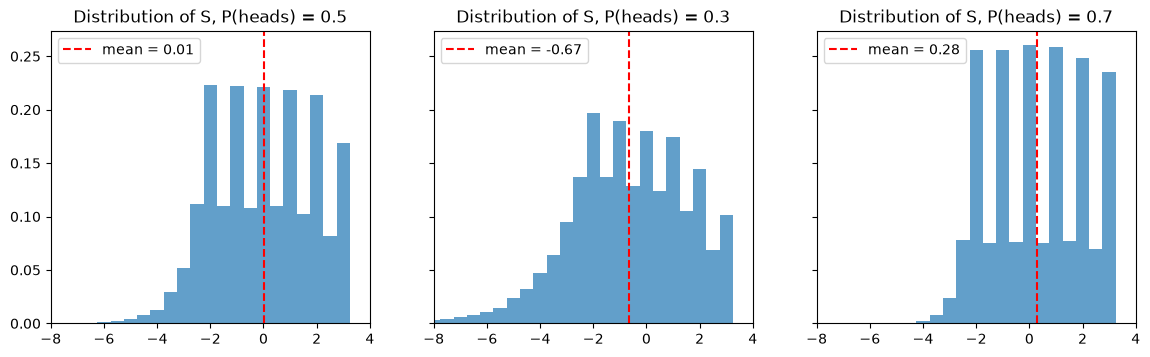

In [5]:
def play_game(p, rng):
    """Play ONE game. p = probability of heads. Returns (N, S)."""
    n_steps = 0
    s = 0.0                                  # money paid by player 2 to player 1
    while True:
        n_steps += 1
        if rng.random() < p:                 # heads with probability p
            z = rng.integers(1, 7)           # player 2 rolls the die
            s += z - 3                       # ... and pays z - 3 (may be negative)
            return n_steps, s                # the game ends at the first heads
        s -= 0.5                             # tails: player 1 pays 0.5 to player 2


fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, p in zip(axes, [0.5, 0.3, 0.7]):
    # Simulate many games and split the results into N and S
    results = np.array([play_game(p, rng) for _ in range(50_000)])
    N_games, S_games = results[:, 0], results[:, 1]

    # Theoretical values from the formulas above
    EN_theory = 1 / p
    ES_theory = 0.5 - 0.5 * (1 / p - 1)
    print(f"p = {p}:  E[N] sim = {N_games.mean():.3f} (theory {EN_theory:.3f})   "
          f"E[S] sim = {S_games.mean():.3f} (theory {ES_theory:.3f})")

    # Histogram of S. The values of S are multiples of 0.5 -> bins centred on them.
    bins = np.arange(S_games.min() - 0.25, S_games.max() + 0.5, 0.5)
    ax.hist(S_games, bins=bins, density=True, alpha=0.7)
    ax.axvline(S_games.mean(), color="red", ls="--", label=f"mean = {S_games.mean():.2f}")
    ax.set_xlim(-8, 4)
    ax.set_title(f"Distribution of S, P(heads) = {p}")
    ax.legend()
plt.savefig(FIG / "01_coin_game.png", dpi=150, bbox_inches="tight")
plt.show()

**d) Biased coin.** With p = 0.3 the game lasts longer and player 1 pays many 0.5's
→ negative mean. With p = 0.7 the game usually ends at once → positive mean
(the die gives +0.5 on average).

## Exercise 3 · Barbershop: a mixture of exponentials (Assignment 1)

Three barbers serve on average 3, 6 and 4 customers per hour, so the service time of
barber *i* is $\text{Exp}(\lambda_i)$ with $\lambda = (3, 6, 4)\ \text{h}^{-1}$.

**Why are the assignment probabilities 3/13, 6/13, 4/13?** In one hour the shop serves
3 + 6 + 4 = 13 customers, of which 3, 6 and 4 are served by each barber.

X = service time of a random customer is a **mixture**:

$$E[X] = \sum_i w_i \frac{1}{\lambda_i} = \frac{3}{13},\qquad
E[X^2] = \sum_i w_i \frac{2}{\lambda_i^2},\qquad \operatorname{Var}X = E[X^2]-E[X]^2 .$$

In [6]:
lam = np.array([3, 6, 4])          # service rates (customers / hour)
w = lam / lam.sum()                # assignment probabilities 3/13, 6/13, 4/13
N = 10_000

# Two-step sampling of a mixture:
# 1) choose the barber for every customer
barber = rng.choice(3, size=N, p=w)
# 2) sample the service time from THAT barber's exponential.
#    WARNING: numpy uses scale = 1 / lambda (the mean), not lambda!
X = rng.exponential(scale=1 / lam[barber])

mean_theory = np.sum(w / lam)
var_theory = np.sum(w * 2 / lam**2) - mean_theory**2
print(f"Mean: simulated = {X.mean():.4f} h, theory = {mean_theory:.4f} h  (~{60*mean_theory:.1f} min)")
print(f"Std : simulated = {X.std():.4f} h, theory = {np.sqrt(var_theory):.4f} h")

Mean: simulated = 0.2335 h, theory = 0.2308 h  (~13.8 min)
Std : simulated = 0.2499 h, theory = 0.2493 h


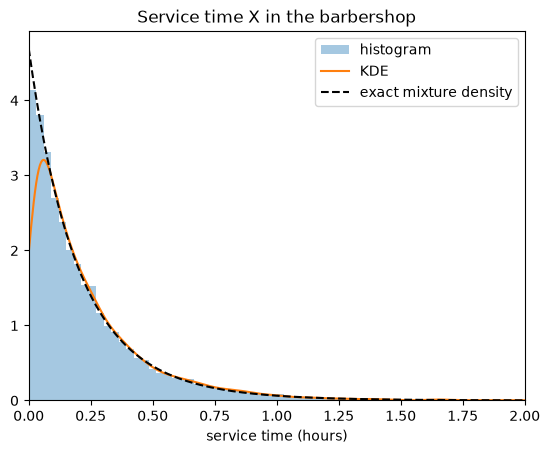

In [7]:
# Approximate density of X: histogram + KDE (kernel density estimate).
# az.plot_kde(X) from ArviZ draws the same KDE curve; here we use scipy directly.
x = np.linspace(0, 2, 400)
exact_pdf = sum(wi * stats.expon(scale=1 / li).pdf(x) for wi, li in zip(w, lam))

plt.hist(X, bins=80, density=True, alpha=0.4, label="histogram")
plt.plot(x, stats.gaussian_kde(X)(x), label="KDE")
plt.plot(x, exact_pdf, "k--", label="exact mixture density")
plt.xlim(0, 2)
plt.xlabel("service time (hours)")
plt.title("Service time X in the barbershop")
plt.legend()
plt.savefig(FIG / "01_barbershop.png", dpi=150, bbox_inches="tight")
plt.show()

### Key takeaways
- `rng.integers(a, b)` excludes `b`; `rng.exponential(scale=1/λ)`; `rng.choice(items, p=probs)`.
- Estimate a probability with `np.mean(boolean_array)`.
- Always compare the simulation with the theoretical value (law of total probability, expectations).